# TP 1 — Régression linéaire
**Machine Learning · Apprentissage supervisé · Régression**

Ce TP reprend **exactement** les exemples de la présentation  :

| Exemple | Diapos | Problème |
|---|---|---|
| Exemple 1 | 8 – 9 | Prédire la note d’un étudiant à partir de ses heures d’étude |
| Exemple 2 | 10 – 11 | Prédire le prix d’un logement à partir de 3 variables |

**Objectifs**
1. Programmer la régression linéaire et la descente de gradient **from scratch**, en Python pur.
2. Refaire les mêmes exemples avec des **bibliothèques** (NumPy, scikit-learn).
3. **Comparer** les résultats pour valider le travail from scratch.


## Rappel de cours (diapos 6 – 7)

Le modèle prédit une valeur continue avec une droite :
$$\hat y = w\,x + b \qquad (\text{plusieurs entrées : } \hat y = w_1x_1 + w_2x_2 + w_3x_3 + b)$$

- $w$ : **poids** (pente de la droite) — appris
- $b$ : **biais** (valeur à l’origine) — appris
- **écart** (résidu) : $e_i = y_i - \hat y_i$

**Erreur à minimiser (MSE)** :
$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n} (y_i - \hat y_i)^2$$

**Gradients** (en dérivant la MSE) :
$$\frac{\partial \text{MSE}}{\partial w_j} = -\frac{2}{n}\sum_i e_i\,x_{ij} = -2\times \text{moy}(e \times x_j) \qquad
\frac{\partial \text{MSE}}{\partial b} = -2\times \text{moy}(e)$$

**Descente de gradient** (η = pas d’apprentissage, choisi par nous) :
$$w := w - \eta\,\frac{\partial \text{MSE}}{\partial w} \qquad b := b - \eta\,\frac{\partial \text{MSE}}{\partial b}$$

On répète : **prédire → mesurer l’erreur → calculer les gradients → corriger**, jusqu’à ce que la MSE ne baisse plus.

In [18]:
# Données
X = [1, 2, 3, 4]   # heures d'étude
Y = [2, 4, 6, 8]   # notes
n = len(X)

### Question 1 — Itération 1, étape 1 : prédire puis mesurer l’erreur
Avec $w = 0$ et $b = 0$, calculer les prédictions $\hat y$, les écarts $y - \hat y$ et la MSE.

**Réponse.** Avec des paramètres nuls, le modèle prédit $\hat y = 0$ pour tout le monde. Les écarts sont donc égaux aux notes : 2 ; 4 ; 6 ; 8.
$$\text{MSE} = \frac{2^2 + 4^2 + 6^2 + 8^2}{4} = \frac{4 + 16 + 36 + 64}{4} = \frac{120}{4} = 30$$

In [19]:
def predire(x, w, b):
    # Prédiction de la droite pour une seule valeur x
    return w * x + b

def ecarts(X, Y, w, b):
    # Écart (résidu) y - ŷ pour chaque exemple
    return [y - predire(x, w, b) for x, y in zip(X, Y)]

def mse(X, Y, w, b):
    # Moyenne des écarts au carré
    e = ecarts(X, Y, w, b)
    return sum(ei ** 2 for ei in e) / len(e)

w, b = 0.0, 0.0
print("Prédictions :", [predire(x, w, b) for x in X])
print("Écarts      :", ecarts(X, Y, w, b))


Prédictions : [0.0, 0.0, 0.0, 0.0]
Écarts      : [2.0, 4.0, 6.0, 8.0]


### Question 2 — Itération 1, étape 2 : calculer les gradients
**Réponse.** On applique les formules du rappel :
- $\text{moy}(e \times x) = (2 + 8 + 18 + 32)/4 = 15$ → $\partial \text{MSE}/\partial w = -2 \times 15 = -30$
- $\text{moy}(e) = (2 + 4 + 6 + 8)/4 = 5$ → $\partial \text{MSE}/\partial b = -2 \times 5 = -10$

Le gradient est **négatif** : augmenter $w$ et $b$ fera baisser l’erreur. Le gradient de $w$ est multiplié par $x$ car $w$ est multiplié par $x$ dans la prédiction.

In [20]:
def gradients(X, Y, w, b):
    e = ecarts(X, Y, w, b)
    n = len(X)
    moy_e_x = sum(ei * xi for ei, xi in zip(e, X)) / n
    moy_e = sum(e) / n
    return -2 * moy_e_x, -2 * moy_e     # (dMSE/dw, dMSE/db)

gw, gb = gradients(X, Y, 0.0, 0.0)
print("Gradient de w :", gw)
print("Gradient de b :", gb)

Gradient de w : -30.0
Gradient de b : -10.0


### Question 3 — Itération 1, étape 3 : mettre à jour $w$ et $b$ ($\eta = 0{,}05$)
**Réponse.** On fait un pas dans le sens **opposé** au gradient :
$$w = 0 - 0{,}05 \times (-30) = 1{,}50 \qquad b = 0 - 0{,}05 \times (-10) = 0{,}50$$

In [21]:
def iteration(X, Y, w, b, eta):
    # Une itération complète de descente de gradient
    gw, gb = gradients(X, Y, w, b)
    return w - eta * gw, b - eta * gb

eta = 0.05
w, b = iteration(X, Y, 0.0, 0.0, eta)
print("w après itération 1 :", w)
print("b après itération 1 :", b)

w après itération 1 : 1.5
b après itération 1 : 0.5


### Question 4 — Itérations 2 et 3 (diapo 9)
Répéter les mêmes étapes et retrouver le tableau de la diapo 9.





In [22]:
def afficher_iteration(num, X, Y, w, b):
    print(f"--- Itération {num} : w = {w:.4f} ; b = {b:.4f}")
    print(f"{'x':>3} {'ŷ':>7} {'écart':>7} {'écart×x':>8} {'écart²':>7}")
    for x, y in zip(X, Y):
        yh = predire(x, w, b)
        e = y - yh
        print(f"{x:>3} {yh:>7.2f} {e:>7.2f} {e*x:>8.2f} {e**2:>7.2f}")
    print(f"MSE = {mse(X, Y, w, b):.4f}")

w, b = 0.0, 0.0
historique = []                       # (w, b, MSE) au début de chaque itération
for k in range(1, 4):
    historique.append((w, b, mse(X, Y, w, b)))
    afficher_iteration(k, X, Y, w, b)
    w, b = iteration(X, Y, w, b, eta)
print(f"\nAprès 3 itérations : w = {w:.4f} ; b = {b:.4f}\n")



--- Itération 1 : w = 0.0000 ; b = 0.0000
  x       ŷ   écart  écart×x  écart²
  1    0.00    2.00     2.00    4.00
  2    0.00    4.00     8.00   16.00
  3    0.00    6.00    18.00   36.00
  4    0.00    8.00    32.00   64.00
MSE = 30.0000
--- Itération 2 : w = 1.5000 ; b = 0.5000
  x       ŷ   écart  écart×x  écart²
  1    2.00    0.00     0.00    0.00
  2    3.50    0.50     1.00    0.25
  3    5.00    1.00     3.00    1.00
  4    6.50    1.50     6.00    2.25
MSE = 0.8750
--- Itération 3 : w = 1.7500 ; b = 0.5750
  x       ŷ   écart  écart×x  écart²
  1    2.33   -0.33    -0.33    0.11
  2    4.08   -0.08    -0.15    0.01
  3    5.83    0.17     0.52    0.03
  4    7.58    0.42     1.70    0.18
MSE = 0.0806

Après 3 itérations : w = 1.7937 ; b = 0.5800



### Question 5 — Entraîner jusqu’à la convergence, puis prédire
soit 500 itérations


In [23]:
def entrainer(X, Y, eta, nb_iter, w=0.0, b=0.0):
    courbe = [mse(X, Y, w, b)]
    for _ in range(nb_iter):
        w, b = iteration(X, Y, w, b, eta)
        courbe.append(mse(X, Y, w, b))
    return w, b, courbe

w_final, b_final, courbe = entrainer(X, Y, eta=0.05, nb_iter=500)
print(f"Après 500 mises à jour : ŷ = {w_final:.4f}·x + {b_final:.4f}   (MSE = {courbe[-1]:.2e})")


Après 500 mises à jour : ŷ = 1.9999·x + 0.0003   (MSE = 1.75e-08)


### Question 6 — Choix du pas d’apprentissage η


η = 0,005 : [30.0, 25.21, 21.18, 17.8, 14.96, 12.58, 10.58, 8.89, 7.48, 6.29, 5.29]
η = 0,15  : [30.0, 67.9, 153.7, 348.1, 788.4, 1785.9, 4045.6]


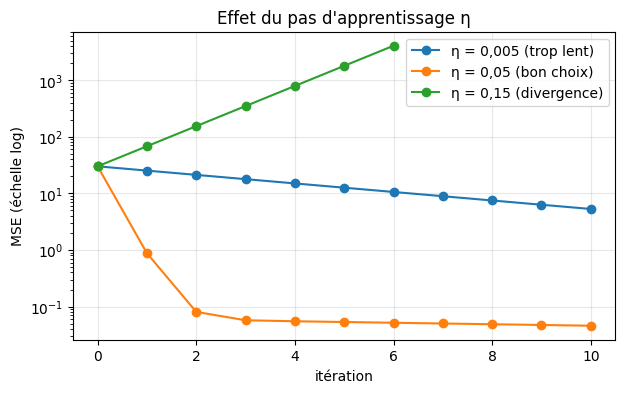

In [24]:
_, _, courbe_petit = entrainer(X, Y, eta=0.005, nb_iter=10)
_, _, courbe_grand = entrainer(X, Y, eta=0.15, nb_iter=6)
print("η = 0,005 :", [round(v, 2) for v in courbe_petit])
print("η = 0,15  :", [round(v, 1) for v in courbe_grand])

import matplotlib.pyplot as plt          # utilisé seulement pour l'affichage
_, _, courbe_bon = entrainer(X, Y, eta=0.05, nb_iter=10)
plt.figure(figsize=(7, 4))
plt.plot(courbe_petit, "o-", label="η = 0,005 (trop lent)")
plt.plot(courbe_bon, "o-", label="η = 0,05 (bon choix)")
plt.plot(courbe_grand, "o-", label="η = 0,15 (divergence)")
plt.yscale("log"); plt.xlabel("itération"); plt.ylabel("MSE (échelle log)")
plt.title("Effet du pas d'apprentissage η"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Exemple 2 : prix d’un logement, 3 entrées (diapos 10 – 11)

| # | $x_1$ surface (×10 m²) | $x_2$ chambres | $x_3$ âge (×10 ans) | $y$ prix (k TND) |
|---|---|---|---|---|
| 1 | 5 | 1 | 2 | 130 |
| 2 | 6 | 2 | 1 | 165 |
| 3 | 8 | 2 | 3 | 195 |
| 4 | 10 | 3 | 1 | 255 |

C’est une **régression multiple** : un poids par variable. Départ : $w_1 = w_2 = w_3 = 0$, $b = 0$, et $\eta = 0{,}003$.

> Les surfaces et les âges sont divisés par 10 (**mise à l’échelle**) pour que les nombres restent du même ordre de grandeur.

In [25]:
# Données  : chaque ligne = (x1, x2, x3)
X2 = [[5, 1, 2],
      [6, 2, 1],
      [8, 2, 3],
      [10, 3, 1]]
Y2 = [130, 165, 195, 255]

### Question 7 — Généraliser le code à plusieurs entrées
La prédiction devient une somme pondérée $\hat y = \sum_j w_j x_j + b$. Chaque poids $w_j$ a son propre gradient $-2 \times \text{moy}(e \times x_j)$ ; le biais garde $-2 \times \text{moy}(e)$. Le code de l’exemple 1 est un cas particulier de celui-ci (une seule variable).

In [26]:
def predire_multi(xs, w, b):
    # xs = liste des entrées d'un exemple, w = liste des poids
    return sum(wj * xj for wj, xj in zip(w, xs)) + b

def ecarts_multi(X, Y, w, b):
    return [y - predire_multi(xs, w, b) for xs, y in zip(X, Y)]

def mse_multi(X, Y, w, b):
    e = ecarts_multi(X, Y, w, b)
    return sum(ei ** 2 for ei in e) / len(e)

def gradients_multi(X, Y, w, b):
    e = ecarts_multi(X, Y, w, b)
    n, p = len(X), len(w)
    gw = [-2 * sum(e[i] * X[i][j] for i in range(n)) / n for j in range(p)]
    gb = -2 * sum(e) / n
    return gw, gb

def iteration_multi(X, Y, w, b, eta):
    gw, gb = gradients_multi(X, Y, w, b)
    w = [wj - eta * gj for wj, gj in zip(w, gw)]
    return w, b - eta * gb

### Question 8 — Itération 1





In [27]:

w2, b2 = [0.0, 0.0, 0.0], 0.0
eta2 = 0.003
gw, gb = gradients_multi(X2, Y2, w2, b2)

print("MSE de départ :", mse_multi(X2, Y2, w2, b2))
print("Gradients :", gw, gb)
w2, b2 = iteration_multi(X2, Y2, w2, b2, eta2)

MSE de départ : 36793.75
Gradients : [-2875.0, -807.5, -632.5] -372.5


### Question 9 — Itérations 2 et 3




In [28]:
w2, b2 = [0.0, 0.0, 0.0], 0.0
params = []
for k in range(5):
    w2, b2 = iteration_multi(X2, Y2, w2, b2, eta2)
    params.append((w2, b2, mse_multi(X2, Y2, w2, b2)))
    print(f"Après itération {k+1} : w = {[round(v, 2) for v in w2]} ; b = {b2:.2f} ; MSE = {params[-1][2]:.0f}")



Après itération 1 : w = [8.62, 2.42, 1.9] ; b = 1.12 ; MSE = 13905
Après itération 2 : w = [13.92, 3.91, 3.05] ; b = 1.80 ; MSE = 5287
Après itération 3 : w = [17.17, 4.83, 3.74] ; b = 2.23 ; MSE = 2042
Après itération 4 : w = [19.17, 5.4, 4.14] ; b = 2.49 ; MSE = 820
Après itération 5 : w = [20.39, 5.76, 4.38] ; b = 2.65 ; MSE = 359


### Question 10 — Convergence et prédiction


 On lance 20 000 itérations. Le signe de $w$ est négatif : **l’âge fait baisser le prix**.

In [29]:
w2, b2 = [0.0, 0.0, 0.0], 0.0
for _ in range(20000):
    w2, b2 = iteration_multi(X2, Y2, w2, b2, eta2)
print(f"w = {[round(v, 4) for v in w2]} ; b = {b2:.4f} ; MSE = {mse_multi(X2, Y2, w2, b2):.5f}")

prix = predire_multi([7, 2, 2], w2, b2)


w = [19.9133, 10.3107, -4.8896] ; b = 29.8069 ; MSE = 0.00351


### Question 11 — Un pas trop grand


In [30]:
w_t, b_t = [0.0, 0.0, 0.0], 0.0
mses = [mse_multi(X2, Y2, w_t, b_t)]
for _ in range(3):
    w_t, b_t = iteration_multi(X2, Y2, w_t, b_t, 0.02)
    mses.append(mse_multi(X2, Y2, w_t, b_t))
print("MSE avec η = 0,02 :", [round(m) for m in mses])


MSE avec η = 0,02 : [36794, 91256, 226532, 562526]


---
# Partie B — Les mêmes exemples avec des bibliothèques

On utilise :
1. **NumPy** : la même descente de gradient, mais écrite avec des calculs vectoriels (sans boucle sur les exemples) ;
2. **scikit-learn `LinearRegression`** : calcule directement la meilleure droite (méthode des moindres carrés), **sans η ni itérations** ;
3. **scikit-learn `SGDRegressor`** : la descente de gradient de scikit-learn.

### Question 12 — Descente de gradient avec NumPy


In [31]:
import numpy as np

# Définition des variables de l'Exemple 1 pour éviter l'erreur NameError
X = [1, 2, 3, 4]
Y = [2, 4, 6, 8]

def descente_numpy(X, y, eta, nb_iter):
    X = np.array(X, dtype=float).reshape(len(y), -1)
    y = np.array(y, dtype=float)
    w, b = np.zeros(X.shape[1]), 0.0
    for _ in range(nb_iter):
        e = y - (X @ w + b)
        w = w - eta * (-2 * X.T @ e / len(y))
        b = b - eta * (-2 * e.mean())
    return w, b

w_np1, b_np1 = descente_numpy(X, Y, 0.05, 500)
w_np2, b_np2 = descente_numpy(X2, Y2, 0.003, 20000)
print("Exemple 1 (NumPy) : w =", w_np1, " b =", b_np1)
print("Exemple 2 (NumPy) : w =", w_np2, " b =", b_np2)

Exemple 1 (NumPy) : w = [1.99988995]  b = 0.00032356379092344487
Exemple 2 (NumPy) : w = [19.91333372 10.31070773 -4.88962164]  b = 29.806937280067242


### Question 13 — Solution exacte avec `LinearRegression`
**Réponse.** `LinearRegression` résout directement le problème des moindres carrés : il trouve **le minimum exact** de la MSE.
- Exemple 1 : les points sont parfaitement alignés ($y = 2x$), on obtient donc exactement $w = 2$, $b = 0$.
- Exemple 2 : 4 logements et 4 paramètres, soit 4 équations à 4 inconnues. La droite passe **exactement** par les 4 points (MSE = 0) avec $w = (20 ; 10 ; -5)$ et $b = 30$. La descente de gradient de la diapo (19,91 ; 10,31 ; −4,89 ; 29,81) **s’en approche** : il faudrait encore plus d’itérations pour l’atteindre.

In [32]:
from sklearn.linear_model import LinearRegression

lr1 = LinearRegression().fit(np.array(X).reshape(-1, 1), Y)
lr2 = LinearRegression().fit(X2, Y2)
print(f"Exemple 1 : w = {lr1.coef_[0]:.4f} ; b = {lr1.intercept_:.4f} ; prédiction x=5 : {lr1.predict([[5]])[0]:.2f}")
print(f"Exemple 2 : w = {np.round(lr2.coef_, 4)} ; b = {lr2.intercept_:.4f} ; prix (7,2,2) : {lr2.predict([[7, 2, 2]])[0]:.2f} k TND")

Exemple 1 : w = 2.0000 ; b = 0.0000 ; prédiction x=5 : 10.00
Exemple 2 : w = [20. 10. -5.] ; b = 30.0000 ; prix (7,2,2) : 180.00 k TND


### Question 14 — Descente de gradient avec `SGDRegressor`




In [33]:
from sklearn.linear_model import SGDRegressor

sgd1 = SGDRegressor(penalty=None, learning_rate="constant", eta0=0.05,
                    max_iter=500, tol=None, shuffle=False).fit(np.array(X).reshape(-1, 1), Y)
sgd2 = SGDRegressor(penalty=None, learning_rate="constant", eta0=0.003,
                    max_iter=20000, tol=None, shuffle=False).fit(X2, Y2)
print(f"Exemple 1 : w = {sgd1.coef_[0]:.4f} ; b = {sgd1.intercept_[0]:.4f}")
print(f"Exemple 2 : w = {np.round(sgd2.coef_, 4)} ; b = {sgd2.intercept_[0]:.4f}")

Exemple 1 : w = 2.0000 ; b = 0.0000
Exemple 2 : w = [19.9977 10.0077 -4.9976] ; b = 29.9970


---
# Partie C — Comparaison et validation
### Question 15 — Les résultats concordent-ils ?
**Réponse.** Le tableau rassemble, pour chaque paramètre, la valeur de la diapo, le Python pur, NumPy et scikit-learn.

In [34]:
import pandas as pd

lignes = [
    ("Ex.1  w", 2.00,  w_final,  w_np1[0], lr1.coef_[0],   sgd1.coef_[0]),
    ("Ex.1  b", 0.00,  b_final,  b_np1,    lr1.intercept_, sgd1.intercept_[0]),
    ("Ex.2  w1", 19.91, w2[0],   w_np2[0], lr2.coef_[0],   sgd2.coef_[0]),
    ("Ex.2  w2", 10.31, w2[1],   w_np2[1], lr2.coef_[1],   sgd2.coef_[1]),
    ("Ex.2  w3", -4.89, w2[2],   w_np2[2], lr2.coef_[2],   sgd2.coef_[2]),
    ("Ex.2  b", 29.81, b2,       b_np2,    lr2.intercept_, sgd2.intercept_[0]),
    ("Ex.2  prix (7,2,2)", 180, predire_multi([7, 2, 2], w2, b2),
        w_np2 @ [7, 2, 2] + b_np2, lr2.predict([[7, 2, 2]])[0], sgd2.predict([[7, 2, 2]])[0]),
]
tableau = pd.DataFrame(lignes, columns=["Paramètre", "Diapo", "Python pur", "NumPy (même GD)",
                                       "LinearRegression (exact)", "SGDRegressor"])
display(tableau.round(3))

# 1) Python pur et NumPy font exactement le même calcul : écart quasi nul
assert np.allclose([w_final, b_final], [w_np1[0], b_np1], atol=1e-9)
assert np.allclose(w2 + [b2], list(w_np2) + [b_np2], atol=1e-6)
# 2) Après convergence, la descente de gradient est proche de la solution exacte (à moins de 0,5 près)
assert np.allclose([w_final, b_final], [lr1.coef_[0], lr1.intercept_], atol=0.01)
assert np.allclose(w2 + [b2], list(lr2.coef_) + [lr2.intercept_], atol=0.5)
print("✅ Python pur = NumPy (même algorithme), et les deux convergent vers la solution de scikit-learn.")

,Paramètre,Diapo,Python pur,NumPy (même GD),LinearRegression (exact),SGDRegressor
0,Ex.1 w,2.00,2.000,2.000,2.0,2.000
1,Ex.1 b,0.00,0.000,0.000,0.0,0.000
2,Ex.2 w1,19.91,19.913,19.913,20.0,19.998
3,Ex.2 w2,10.31,10.311,10.311,10.0,10.008
4,Ex.2 w3,-4.89,-4.890,-4.890,-5.0,-4.998
5,Ex.2 b,29.81,29.807,29.807,30.0,29.997
6,"Ex.2 prix (7,2,2)",180.00,180.042,180.042,180.0,180.001


✅ Python pur = NumPy (même algorithme), et les deux convergent vers la solution de scikit-learn.


### Question 16 — Visualiser l’apprentissage de l’exemple 1
**Réponse.** Les droites successives se redressent vers les points, comme sur la diapo 9.

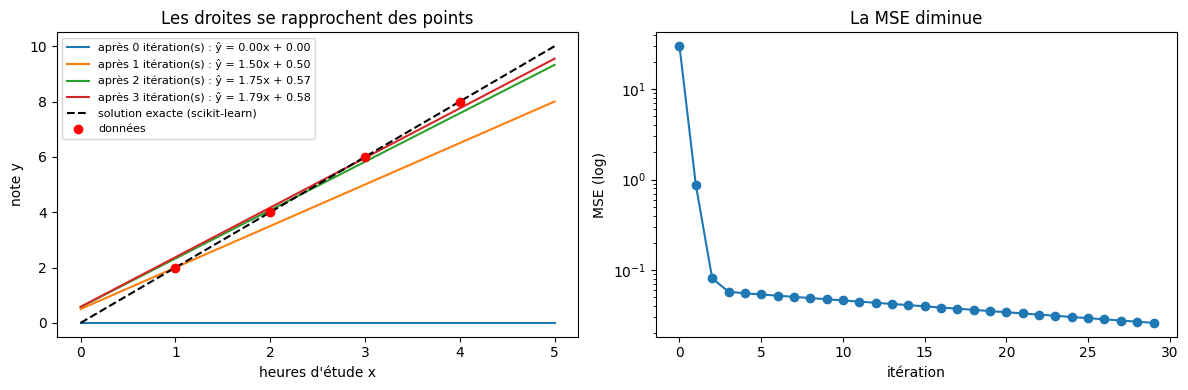

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
xs = np.linspace(0, 5, 50)
w_, b_ = 0.0, 0.0
for k in range(4):
    ax[0].plot(xs, w_ * xs + b_, label=f"après {k} itération(s) : ŷ = {w_:.2f}x + {b_:.2f}")
    w_, b_ = iteration(X, Y, w_, b_, 0.05)
ax[0].plot(xs, lr1.coef_[0] * xs + lr1.intercept_, "k--", label="solution exacte (scikit-learn)")
ax[0].scatter(X, Y, color="red", zorder=5, label="données")
ax[0].set_xlabel("heures d'étude x"); ax[0].set_ylabel("note y"); ax[0].legend(fontsize=8)
ax[0].set_title("Les droites se rapprochent des points")
ax[1].plot(courbe[:30], "o-"); ax[1].set_yscale("log")
ax[1].set_xlabel("itération"); ax[1].set_ylabel("MSE (log)"); ax[1].set_title("La MSE diminue")
plt.tight_layout(); plt.show()